#  Regression
**OPIM 5603: Statistics in Business Analytics - University of Connecticut**

Please see LMW Chapter 13 ('Correlation and Linear Regression') for more details and examples.

--------------------------------------------------------------------------


# Slide 12: Sales and Calls - (1) Finding the relationship by hand

The formula for the coefficient coefficient is given by:

<center>
$r = \frac{\Sigma(X - \bar{X})(Y - \bar{Y})}{(n-1)s_xs_y}$
</center>

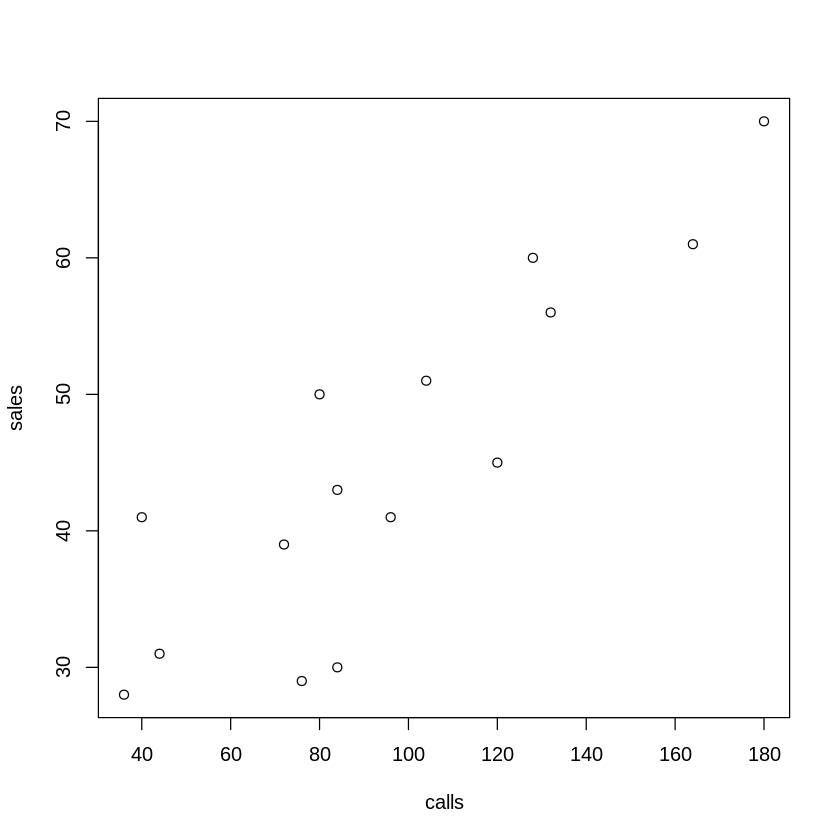

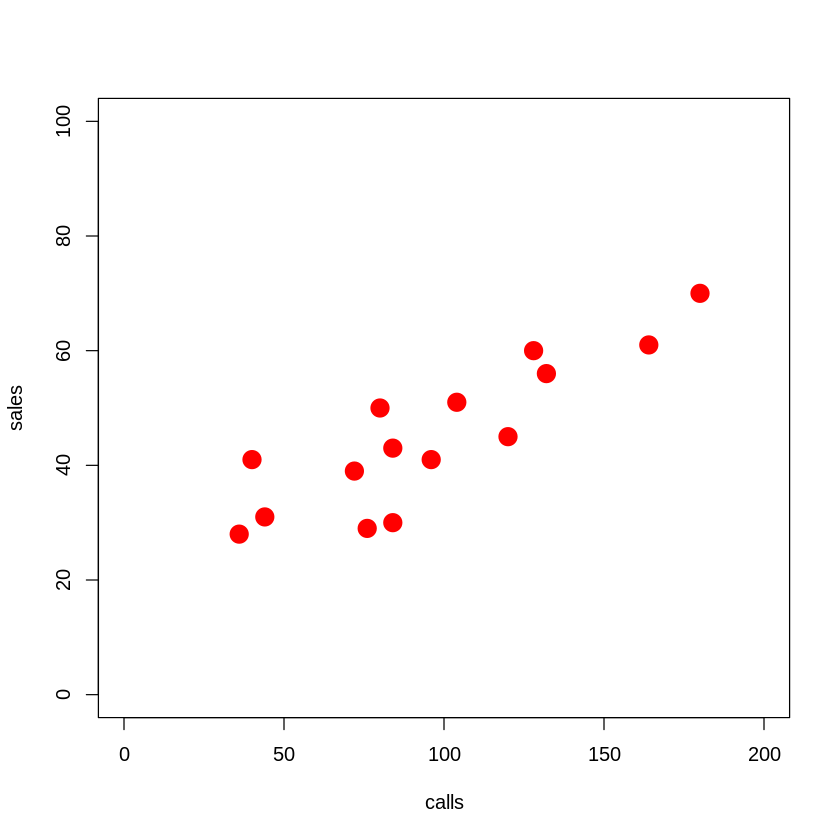

In [3]:
# Setup the data
calls = c(96,40,104,128,164,76,72,80,36,84,180,132,120,44,84) # X
sales = c(41,41,51,60,61,29,39,50,28,43,70,56,45,31,30) #  Y

# make a plot
plot(x=calls, y=sales)

# Or you can make it a little prettier using the following code)
plot(x=calls, y=sales, pch=19, col='red', xlim=c(0,200), ylim=c(0,100), cex=2)

Let's look at the deviation from the mean and their products so that we can calculate the correlation coefficient, $r$.

In [5]:
# first, let's turn this into a data frame (df) for ease
dataframe = as.data.frame(cbind(calls, sales))    # you could use cbind() to join everything together in one tight package
dataframe # looks good!

calls,sales
<dbl>,<dbl>
96,41
40,41
104,51
128,60
164,61
76,29
72,39
80,50
36,28


In [6]:
# Compute the r
r <- cor(dataframe$calls, dataframe$sales)  # This is to caculate the r
r

# Alternatively, you can do multiple-step cacualtion by following the equation
  # r = sum(X_minus_Xbar*Y_minus_Ybar) / ((nrow(df) -1)*sx*sy)
  # r = round(r,3)
  # r

[1] 0.8646318

In [10]:
# R gives us a short-cut to generate the entire regression output:
myfit = lm(dataframe$sales~dataframe$calls, data=dataframe)    # lm is used to fit linear models.
summary(myfit)


Call:
lm(formula = dataframe$sales ~ dataframe$calls, data = dataframe)

Residuals:
    Min      1Q  Median      3Q     Max 
-11.873  -2.861   0.255   3.511  10.595 

Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)      19.9800     4.3897   4.552 0.000544 ***
dataframe$calls   0.2606     0.0420   6.205 3.19e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 6.72 on 13 degrees of freedom
Multiple R-squared:  0.7476,	Adjusted R-squared:  0.7282 
F-statistic:  38.5 on 1 and 13 DF,  p-value: 3.193e-05


In [ ]:
# Alternatively, you can do multiple-step cacualtion by following the equation

# Compute the X - Xbar and Y - Ybar
  # X_minus_Xbar = df$calls - mean(df$calls)
  # Y_minus_Ybar = df$sales - mean(df$sales)
# Compute the sx and sy
  # sx = round(sd(df$calls),2)
  # sy = round(sd(df$sales),2)

# Calculate b1
  # b1 = r*sy/sx
  # b1 = round(b1,4)
  # b1

  # calculuate b0
  # Ybar = mean(df$sales)
  # Xbar = mean(df$calls)

  # b0 = Ybar - b1*Xbar
  # b0 = round(b0, 4)
  # b0

### Interpretation
Thus, the regression equation is $\hat{Y} = 19.98 + 0.26X$. So if a salesperson makes 100 calls, he or she can expect to sell 46.0432 copiers, found by The $b1$ value of 0.2608 indicates that for each additional sales call made the sales representative can expect to increase the number of copiers sold by about 0.26. To put it another way, five additional sales calls in a month will result in about one more copiers being sold, found by $0.2608 * (5) = 1.304$

The $b0$ value of 19.9632 is the point where the equation crosses the Y-axis. A
literal translation is that if no sales calls are made, that is, 19.9632 copiers
will be sold. Note that is outside the range of values included in the sample
and, therefore, should not be used to estimate the number of copiers sold. The sales calls ranged from 36 to 180, so estimates should be limited to that range (in other words - don't extrapolate beyond this range!).

## Sldie 12: Sales and Calls - (2) Drawing The Regression Line


In [13]:
# let's add our predictions to this
dataframe$preds = 19.9632 + 0.2608*dataframe$calls
dataframe # looks great! agrees with your example in the book too.

calls,sales,preds
<dbl>,<dbl>,<dbl>
96,41,45.0000
40,41,30.3952
104,51,47.0864
128,60,53.3456
164,61,62.7344
76,29,39.7840
72,39,38.7408
80,50,40.8272
36,28,29.3520


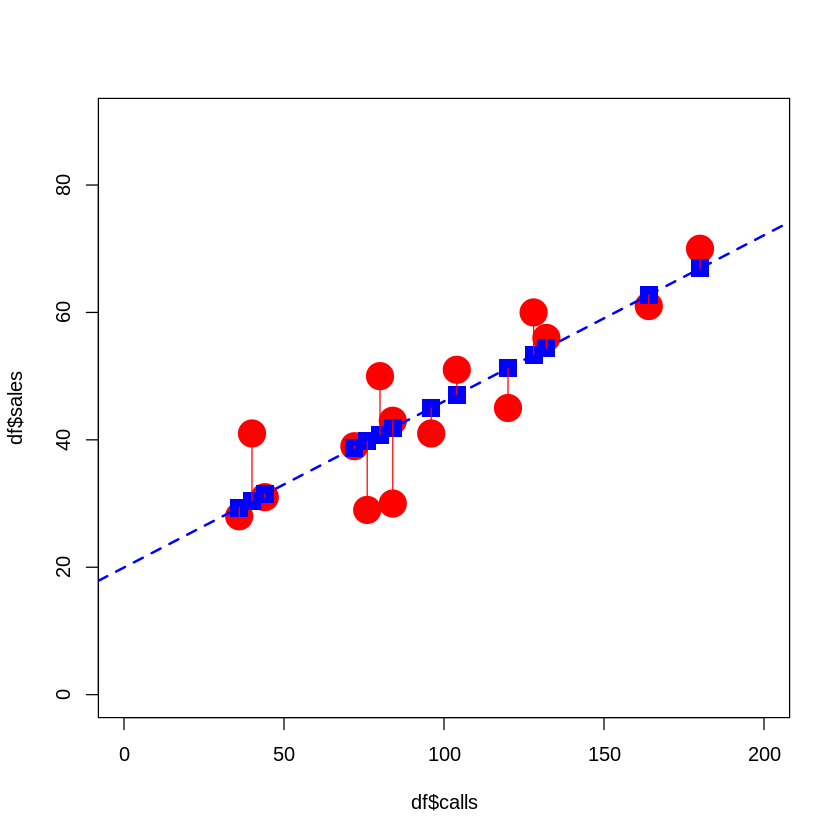

In [ ]:
# plot the actual data as red dots
plot(df$calls, df$sales, pch=19, col='red', cex=3, xlim=c(0,200), ylim=c(0,90))
# add the estimated data points as blue squares
points(df$calls, df$preds, pch=15, col='blue', cex=2)
# add the regression equation
abline(a = 19.9632, b = 0.2608, col = 'blue', lty=2, lwd=2)
# curve(19.9632 + 0.2608*df$calls,col="blue") # you can plot the regression equation from 'res'!!!
segments(df$calls, df$sales, df$calls, df$preds,col="red")

# Check the regression line pass through the point (X_bar, Y_bar)
# points(mean(df$calls), mean(df$sales), pch=17, col='yellow', cex=2)

# Check the sum of residuals is zero
# sum(df$sales - df$preds)

# Check sample covariance between the regressors and the OLS residuals is zero
# sum((df$sales - df$preds)*df$calls)

## Slide 12: Sales and Calls - (3) Use a hypothesis test

The null and alternative hypotheses are

$H_0: \beta_1 = 0$

$H_1: \beta_1 \neq 0$

Here is the formula to calculate our test statistic, $t$:

<center>
$t = \frac{b1-0}{s_b}$
</center>

And the formula for the **standard error of the slope estimate** ($s_b$) is given by:
<center>
$s_b = \frac{\sqrt{\Sigma(y_i – \hat{y_i})^2 / (n – 2)}}{\sqrt{\Sigma(x_i – \bar{x})^2 }}$
</center>

$s_b$ is a value similar to the standard error of the mean - it's the uncertainty associated with our estimate. It represents the average distance that your observed values deviate from the regression line.

Now, regarding $t$, it must look silly to have the $b-0$ in the numerator, but it helps reinforce/remind you that you are ensuring that $b$ is not 0.

Here's a reference for $s_b$ (standard error of regression slope formula, not provided in LMW):
* https://www.statisticshowto.com/find-standard-error-regression-slope/

In [ ]:
## Application to Sales Example

# first, since we see that t is a function of sb, let's calculate sb first
Y_minus_Ypred = df$sales - df$preds
n = nrow(df)
X_minus_Xbar = df$calls - mean(df$calls)

# for convenince, I'll break this formula up into "top" and "bottom" so it's not a bear
top = sqrt((sum((Y_minus_Ypred)^2))/(n-2))
bottom = sqrt(sum((X_minus_Xbar)^2))
sb = top/bottom
sb

[1] 0.04200185

So our value of $s_b$ is $0.042$ (due to rounding). Now let's calculate $t$, our test statistic.

In [ ]:
# t is a function of b and sb, it's very easy to calculate

# remember, we already calculated b before (scroll up for a refresher)... it's from our regression eqn
X_minus_Xbar = df$calls - mean(df$calls)
Y_minus_Ybar = df$sales - mean(df$sales)
sx = sd(df$calls)
sy = sd(df$sales)
r = sum(X_minus_Xbar*Y_minus_Ybar) / ((nrow(df) -1)*sx*sy)

# pay attention to what b is a function f
b = r*sy/sx
# here's t, sb was calculated above
t = (b - 0)/sb
t # matches example in the book.

[1] 6.205085

So our value of $t$ is $6.205$. We can already tell with such a monster value of $t$, you reject the null hypothesis.

Now we need to calculate our critical value. The t-distribution is the test statistic; there are $13$ degrees of freedom, found by
$n - 2 = 15 - 2$. We use the .05 significance level. We will calculate below that the critical value is 2.16. Our decision rule is to reject the null hypothesis if the $t$ (test statistic) computed from formula is greater than 2.160.

In [ ]:
# here are our critical values which will define our rejection region
alpha = 0.05
t.half.alpha = qt(1-alpha/2, df=15-2)
c(-t.half.alpha, t.half.alpha)

# REMEMBER - OUR CRITICAL VALUES ARE DIFFERENT THAN THE BOOK!
# WE ARE DOING A TWO-TAILED TEST, THEY ARE DOING A ONE-TAILED TEST

[1] -2.160369  2.160369

And we can get the value of the p-value handidly

In [ ]:
2*(1-pt(t, df=15-2)) # remember, we multiply the p-value times two
                     # because the variable order could have been reversed

[1] 3.192791e-05

But let's plot it to be sure. Seeing is believing!

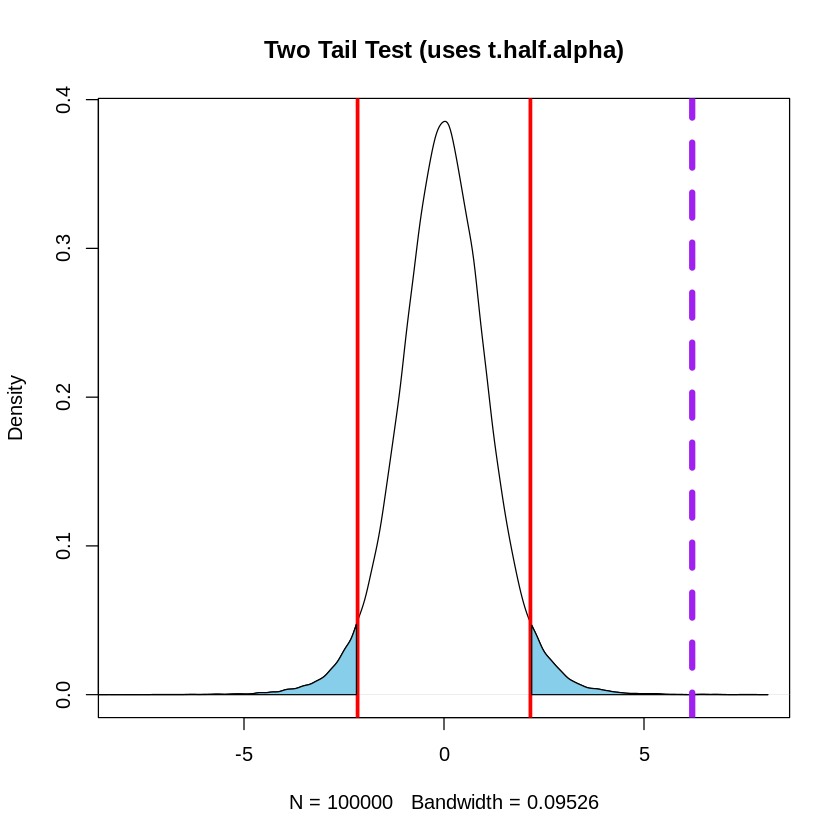

In [ ]:
# all of this code is the same as above

tmp = rt(100000, df=10-2)
plot(density(tmp), main='Two Tail Test (uses t.half.alpha)',
      xlim=c(-8,8))
# add a line on the left tail
abline(v=t.half.alpha, col='red', lwd=3)
# add the shaded polygon to the RIGHT
dens = density(tmp) # store those value
x1 <- min(which(dens$x >= t.half.alpha))
x2 <- max(which(dens$x <= Inf))
with(dens, polygon(x=c(x[c(x1,x1:x2,x2)]), y= c(0, y[x1:x2], 0), col="skyblue"))

# add a line on the left tail
abline(v=-t.half.alpha, col='red', lwd=3)
# add the shaded polygon to the LEFT
dens = density(tmp) # store those value
x1 <- min(which(dens$x >= -Inf))
x2 <- max(which(dens$x <= -t.half.alpha))
with(dens, polygon(x=c(x[c(x1,x1:x2,x2)]), y= c(0, y[x1:x2], 0), col="skyblue"))

# now add our purple line
abline(v=t, lty=2, lwd=5, col='purple')

REJECT THE NULL HYPOTHESIS THAT $\beta = 0$!  The independent variable referring to the number of
sales calls is useful for obtaining a better estimate of sales.

It's always a good idea to summarize your thoughts like this - otherwise you might get lost in stats jargon land.

# Slide 18: Coefficient of Determination ($R^2$)
You'll quickly pick out the $R^2$ value from the summary above. You'll see many different representations of this - for example, from our maximum likelihood estimate lectures we saw...

$R^2 = 1 - \frac{SSE}{SST}$

where $SSE$ were the squared errors in our fitted model vs. $SST$ which were the squared errors in our baseline model. You can pick this out of the model summary below and calculate.

In [14]:
# R gives us a short-cut to get R square
summary(myfit)$r.squared

# Alternatively, you can do multiple-step cacualtion by following the equation

  # from our model
  # SSE = sum((df$preds - df$sales)^2)
  # SSE

  # from the baseline model
  # SST = sum((df$sales - mean(df$sales))^2)
  # SST

  # all together now!
  # 1 - SSE/SST

[1] 0.7475881

## Slide 20: The Standard Error of Estimate
The **standard error of the estimate** ($s_{yx}$) should look very familiar to you.

<center>
$s_{yx} = \sqrt{\frac{\Sigma(Y-\hat{Y})^2}{n-2}}$
</center>

In fact, it is just the numerator of the **standard error of slope** ($s_b$), which we talked a lot about.

<center>
$s_b = \frac{\sqrt{\Sigma(y_i – \hat{y_i})^2 / (n – 2)}}{\sqrt{\Sigma(x_i – \bar{x})^2 ]}}$
</center>

Do you see it?!

Again, as we mentioned before, If the standard error of estimate is small, this indicates that the data are relatively
close to the regression line and the regression equation can be used to predict Y
with little error. If the standard error of estimate is large, this indicates that the data
are widely scattered around the regression line, and the regression equation will not
provide a precise estimate of Y.

In other words, the $s_b$ goes towards 0 when we are more confident in our $\beta$ estimates... there is less uncertainty!

In practice, you want to look at the output from R and look BOTH at the coefficient and the standard error of slope (which is a function of the standard error of the estimate).

## Summary: Relationships between Correlation Coefficient, Coefficient of Determination and Standard Error of Estimate
Let's try to tease out what's going on here...

* We previously described the standard error of estimate ($s_{yx})$. Recall that it measures
how close the actual values are to the regression line. As a refresher, here is that equation again: <center>
$s_{yx} = \sqrt{\frac{\Sigma(Y-\hat{Y})^2}{n-2}}$
</center>


* When the standard error is
small, it indicates that the two variables are closely related. In the calculation of the
standard error, the key term is: $\Sigma(Y-\hat{Y})^2$
  * If the value of this term is small, then the standard error will also be small.

* The correlation coefficient measures the strength of the linear association
between two variables. When the points on the scatter diagram appear close to the
line, we note that the correlation coefficient tends to be large. Therefore, the correlation coefficient and the standard error of the estimate are inversely related. As the
strength of a linear relationship between two variables increases, the correlation
coefficient increases and the standard error of the estimate decreases.

* We previously saw the square of the correlation coefficient is the coefficient of
determination. The coefficient of determination measures the percentage of the variation in Y that is explained by the variation in X.

* The final observation that relates the correlation coefficient ($r$), the coefficient of
determination ($R^2$), and the standard error of the estimate ($s_{yx}$) is to show the relationship
between the standard error of the estimate and $\text{SSE}$.
  * Recall that the sum of squared errors (the squared error from your fitted model is $SSE = \Sigma(Y_i - \hat{Y})^2$. We then plugged this into $R^2 = 1 - \text{SSE}/\text{SST}$.
  * Therefore, another way we can write the standard error of the estimate is: $s_{yx} = \sqrt{\frac{\text{SSE}}{n-2}}$.
    * **WOAH!** Which means your standard error of the estimate is a function of how well your model fits...

Take a minute to let this gel. Go re-read the formulas and appreciate how all of this is related.

# Slide 23: Interval Estimates of Prediction (Confidence and Prediction Intervals)
This resource/reading is for multiple linear regression, but is a very good (includes other topics as well!)
* https://daviddalpiaz.github.io/appliedstats/multiple-linear-regression.html

* The first interval estimate is called a confidence interval. This is used when
the regression equation is used to predict the mean value of $Y$ for a given value of $X$.
For example, we would use a confidence interval to estimate the mean salary of all
executives in the retail industry based on their years of experience. To determine
the confidence interval for the mean value of $Y$ for a given $X$, the formula is:
<center>
$\hat{Y} \pm t(s_{yx}) \sqrt{\frac{1}{n}+\frac{(X-\bar{X})^2}{\Sigma(X_i-\bar{X})^2}}$
</center>
* The second interval estimate is called a prediction interval. This is used when
the regression equation is used to predict an individual $Y$ (n=1) for a given value
of $X$. For example, we would estimate the salary of a particular retail executive who
has 20 years of experience. To determine the prediction interval for an estimate of
an individual for a given $X$, the formula is:
<center>
$\hat{Y} \pm t(s_{yx}) \sqrt{1 + \frac{1}{n}+\frac{(X-\bar{X})^2}{\Sigma(X_i-\bar{X})^2}}$
</center>

Note that the **ONLY** difference from these two bands (confidence and prediction) is the inclusion of a $+1$ in the prediction interval formula. By doing this, we will get a wider band for the prediction interval. Always be thinking about how to interrogate a formula...


## Slide 23: Interval Estimates (1) Confidence Interval: Just use R (concise)
Of course, that was a lot of work and IMHO a very small reward. Here is how you return the confidence intervals for ALL rows in the dataframe, which is more useful.

In [ ]:
CI = predict(？, ？, interval="？")
CI

,fit,lwr,upr
1,45.0000,41.25139,48.74861
2,30.4050,24.09051,36.71949
3,47.0850,43.26675,50.90325
4,53.3400,48.59834,58.08166
5,62.7225,55.50277,69.94223
6,39.7875,35.62270,43.95230
7,38.7450,34.40972,43.08028
8,40.8300,36.81006,44.84994
9,29.3625,22.75242,35.97258
10,41.8725,37.96895,45.77605


... you could use `cbind()` to join everything together in one tight package. That last row (11) is our pretend '25 calls' and it corresponds to our worked out math.

In [ ]:
# a tight package
df = cbind(？, ？)
df # TADA!

,calls,sales,preds,fit,lwr,upr,fit,lwr,upr
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,96,41,45.0000,45.0000,41.25139,48.74861,45.0000,41.25139,48.74861
2,40,41,30.3952,30.4050,24.09051,36.71949,30.4050,24.09051,36.71949
3,104,51,47.0864,47.0850,43.26675,50.90325,47.0850,43.26675,50.90325
4,128,60,53.3456,53.3400,48.59834,58.08166,53.3400,48.59834,58.08166
5,164,61,62.7344,62.7225,55.50277,69.94223,62.7225,55.50277,69.94223
6,76,29,39.7840,39.7875,35.62270,43.95230,39.7875,35.62270,43.95230
7,72,39,38.7408,38.7450,34.40972,43.08028,38.7450,34.40972,43.08028
8,80,50,40.8272,40.8300,36.81006,44.84994,40.8300,36.81006,44.84994
9,36,28,29.3520,29.3625,22.75242,35.97258,29.3625,22.75242,35.97258


## Slide 23: Interval Estimates (2) Prediction Interval: Just use R (concise)

R rocks - look how easy this is... you can update the formula to get the previous example to run.

Recall the interpretation here.

In [ ]:
PI = predict(？, ？, interval="？")
PI

,fit,lwr,upr
1,45.0000,30.00556,59.99444
2,30.4050,14.57294,46.23706
3,47.0850,32.07300,62.09700
4,53.3400,38.06700,68.61300
5,62.7225,46.50814,78.93686
6,39.7875,24.68364,54.89136
7,38.7450,23.59324,53.89676
8,40.8300,25.76544,55.89456
9,29.3625,13.41025,45.31475
10,41.8725,26.83857,56.90643


Note how PI is OF COURSE wider than CI.

In [ ]:
CI # CI is always smaller than PI

The CI was between 40.9 and 56.2 and the PI was between 24.47 and 72.62. Why the difference? CI is for the average response of Y given X values - PI is for making the exact prediction Y for a row with those exact given X values.

At a high-level, you are able to make a tighter interval when you are talking about the 'average response' (people who made 25 phone calls) vs. a 'point response' (Dave who made 25 phone calls).

On your own, you could add the PI to your df, but you will likely need to rename some columns so it is not confusing.

## Slide 23: Graphing CI and PI
Let's add these lines to our scatterplot.

Here's a quick way to make preds and store them in your original df (something I do all the time).

Don't forget to sort by X!

In [ ]:
# make predictions
preds = predict(myfit, df)
preds

1       2       3       4       5       6       7       8       9      10 
45.0000 30.4050 47.0850 53.3400 62.7225 39.7875 38.7450 40.8300 29.3625 41.8725 
     11      12      13      14      15 
66.8925 54.3825 51.2550 31.4475 41.8725

In [ ]:
# add them as a new column in your df
df$preds = preds
df

calls,sales,preds
<dbl>,<dbl>,<dbl>
96,41,45.0000
40,41,30.4050
104,51,47.0850
128,60,53.3400
164,61,62.7225
76,29,39.7875
72,39,38.7450
80,50,40.8300
36,28,29.3625


In [ ]:
# add the prediction interval
PI = predict(myfit, df, interval="prediction")
CI = predict(myfit, df, interval="confidence")
df = cbind(df, PI, CI)
# rename columns
colnames(df)[4] = 'PI_fit'
colnames(df)[5] = 'PI_lwr'
colnames(df)[6] = 'PI_upr'
df

,calls,sales,preds,PI_fit,PI_lwr,PI_upr,fit,lwr,upr
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,96,41,45.0000,45.0000,30.00556,59.99444,45.0000,41.25139,48.74861
2,40,41,30.4050,30.4050,14.57294,46.23706,30.4050,24.09051,36.71949
3,104,51,47.0850,47.0850,32.07300,62.09700,47.0850,43.26675,50.90325
4,128,60,53.3400,53.3400,38.06700,68.61300,53.3400,48.59834,58.08166
5,164,61,62.7225,62.7225,46.50814,78.93686,62.7225,55.50277,69.94223
6,76,29,39.7875,39.7875,24.68364,54.89136,39.7875,35.62270,43.95230
7,72,39,38.7450,38.7450,23.59324,53.89676,38.7450,34.40972,43.08028
8,80,50,40.8300,40.8300,25.76544,55.89456,40.8300,36.81006,44.84994
9,36,28,29.3625,29.3625,13.41025,45.31475,29.3625,22.75242,35.97258


In [ ]:
# sort by X (calls)
df = df[order(df$calls),]
df

,calls,sales,preds,PI_fit,PI_lwr,PI_upr,fit,lwr,upr
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
9,36,28,29.3625,29.3625,13.41025,45.31475,29.3625,22.75242,35.97258
2,40,41,30.4050,30.4050,14.57294,46.23706,30.4050,24.09051,36.71949
14,44,31,31.4475,31.4475,15.72818,47.16682,31.4475,25.42124,37.47376
7,72,39,38.7450,38.7450,23.59324,53.89676,38.7450,34.40972,43.08028
6,76,29,39.7875,39.7875,24.68364,54.89136,39.7875,35.62270,43.95230
8,80,50,40.8300,40.8300,25.76544,55.89456,40.8300,36.81006,44.84994
10,84,43,41.8725,41.8725,26.83857,56.90643,41.8725,37.96895,45.77605
15,84,30,41.8725,41.8725,26.83857,56.90643,41.8725,37.96895,45.77605
1,96,41,45.0000,45.0000,30.00556,59.99444,45.0000,41.25139,48.74861



Call:
lm(formula = y ~ x)

Residuals:
    Min      1Q  Median      3Q     Max 
-11.873  -2.861   0.255   3.511  10.595 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  19.9800     4.3897   4.552 0.000544 ***
x             0.2606     0.0420   6.205 3.19e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 6.72 on 13 degrees of freedom
Multiple R-squared:  0.7476,	Adjusted R-squared:  0.7282 
F-statistic:  38.5 on 1 and 13 DF,  p-value: 3.193e-05


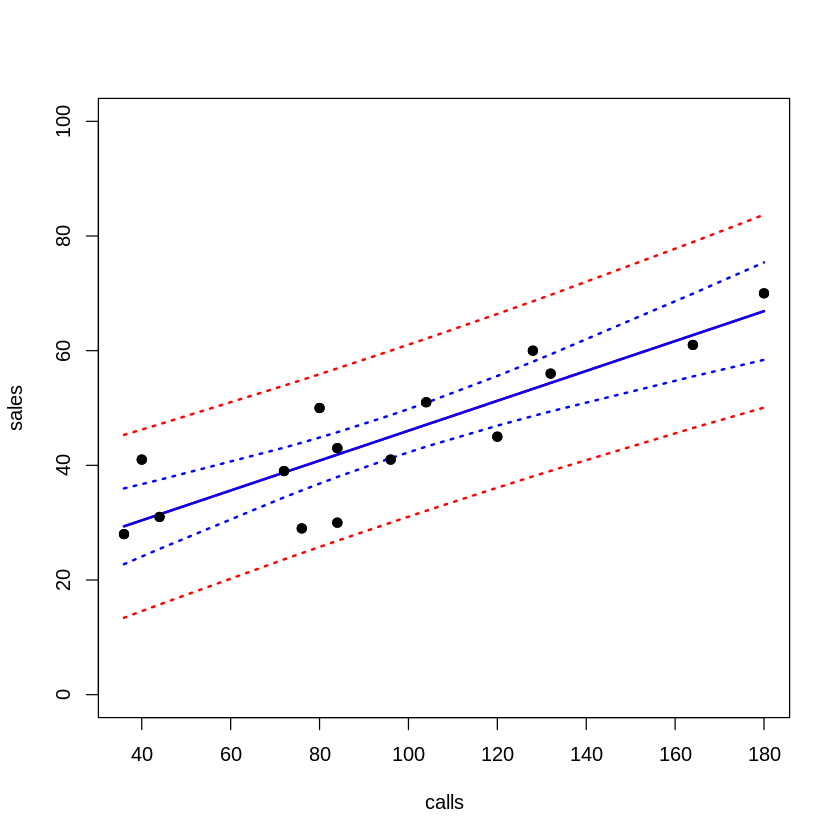

In [ ]:
x = df$calls
y = df$sales
# prepare plot, fit model, get predictions,
# add lines for confidence limits and regression line, add points
plot(x, y, ylim=c(0,100), xlab='calls', ylab='sales')
m = lm(y~x) # your model
summary(m)

# PI
lines(df$calls,df$PI_fit,lwd=2, col='red')
lines(df$calls,df$PI_lwr,lty=3, lwd=2, col='red')
lines(df$calls,df$PI_upr,lty=3, lwd=2, col='red')

# CI
lines(df$calls,df$fit,lwd=2, col='blue')
lines(df$calls,df$lwr,lty=3, lwd=2, col='blue')
lines(df$calls,df$upr,lty=3, lwd=2, col='blue')

# points
points(x,y,pch=19, col='black')

# Regression: Example
## Advertisement and Sales

Find the relationship between advertisement and sales.

a. Conducted a scatter plot between advertisement and sales.

b. Determine the regression equation

c. What is the estimated sales?

d. What is the value of SST, SSR, and SSE? Can you show that SSE + SSR = SST?

e. How do you use SST, SSR, and SSE to calculate $R^2$? Compare it with the $R^2$ in the summary of regression results.

f. Determine the 95% confidence interval for the mean of sales given we spend $65000 in advertising.

g. Determine the 95% prediction interval for sales given we spend $65000 in advertising.

In [ ]:
# Housekeeping
install.packages("readr")
library(readr)
AdvertisingSales <- read_csv("sample_data/AdvertisingSales.csv")
View(AdvertisingSales)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Rows: 10 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (3): Obs, Advertising, ActualSales

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Obs,Advertising,ActualSales
<dbl>,<dbl>,<dbl>
1,30,184.4
2,40,279.1
3,40,244.1
4,50,314.2
5,60,382.2
6,70,450.2
7,70,423.6
8,70,410.2
9,80,500.4


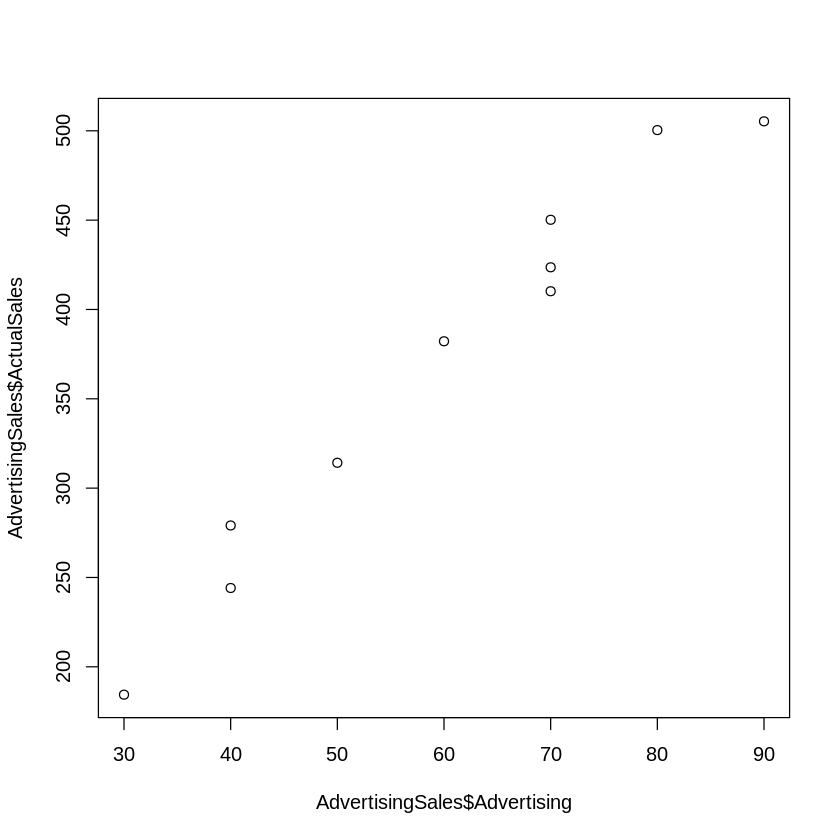

In [ ]:
# a. Scatterplot
plot(？)

In [ ]:
# b. Determine the regression
reg <- lm(？)
summary(reg)


Call:
lm(formula = ActualSales ~ Advertising, data = AdvertisingSales)

Residuals:
   Min     1Q Median     3Q    Max 
-30.56 -14.57  -0.47  18.23  25.33 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  36.3876    21.9738   1.656    0.136    
Advertising   5.5497     0.3501  15.853 2.51e-07 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 20.41 on 8 degrees of freedom
Multiple R-squared:  0.9691,	Adjusted R-squared:  0.9653 
F-statistic: 251.3 on 1 and 8 DF,  p-value: 2.508e-07


In [ ]:
# c. Two ways of finding the estimated value
AdvertisingSales$predict <- ？
AdvertisingSales$predict

AdvertisingSales$predict1 <- ？
AdvertisingSales$predict1

[1] 44.20565 46.81165 46.81165 49.41765 52.02365 54.62965 54.62965 54.62965
 [9] 57.23565 59.84165

1        2        3        4        5        6        7        8 
202.8788 258.3759 258.3759 313.8729 369.3700 424.8671 424.8671 424.8671 
       9       10 
480.3641 535.8612

In [ ]:
# d. Find SST, SSR, and SSE
SST <- sum((AdvertisingSales$ActualSales - sales_bar)^2)
SSR <- sum((AdvertisingSales$predict1 - sales_bar)^2)
SSE <- sum((AdvertisingSales$ActualSales - AdvertisingSales$predict1)^2)

# Check SSR + SSE = SST
SSR + SSE
SST

# Find R_squared
R_squared <- SSR/SST
R_squared
# Alternatively, try use R code to get R squared

[1] 108050.8

[1] 108050.8

[1] 0.9691499

In [ ]:
## CI and PI
testdata <- data.frame(?)
CI <- predict(?, ?, interval = "?")
CI

PI <- predict(?, ?, interval = "?")
PI

,fit,lwr,upr
1,397.1185,381.6957,412.5414


,fit,lwr,upr
1,397.1185,347.5849,446.6522
